# Transforms, from one comp star to an ensemble

A walk through how the app transforms photometry, using the app's own code on one real
session: **CY Aqr on 2026-09-05**, 218 frames each in B, V and R (fixed 8 px aperture).
VPhot measured the same frames twice:

- **single comp:** comp 104, check 117, plus TransformApplier's (TA's) output for it
- **ensemble:** comps 104 + 110 + 140, check 117, plus VPhot's General Report

Because the frames are the same, every ensemble result below can be checked against a
single-comp one.

Sections:
1. What VPhot gives you for one frame
2. What a transform corrects
3. The single-comp transform by hand, checked against TA
4. What an ensemble report contains
5. The ensemble transform two ways: against the average comp, and per comp then averaged
6. Why the two agree, and when they wouldn't
7. What the average hides: the spread across comps
8. Summary

In [1]:
import inspect
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from photometry_workbench.parsing.aavso_report import parse_aavso_report, _parse_notes
from photometry_workbench.parsing.general_report import parse_general_report
from photometry_workbench.parsing.chart_photometry import ChartMag, fetch_chart_photometry
from photometry_workbench.transform.coefficients import parse_report_header
from photometry_workbench.transform import engine

pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", None)  # show every column, no ... in the middle
pd.set_option("display.width", None)        # let wide tables scroll instead of wrapping
SESSION = Path("data/cy-aqr-2026-09-05")   # relative to this notebook

single_report = parse_aavso_report(SESSION / "single-comp-104/AAVSOReport_CY-Aqr_VBR_20260905.txt")       # comp 104
single = single_report.df
ta = parse_aavso_report(SESSION / "single-comp-104/AAVSOReport_CY-Aqr_VBR_20260905_TA.txt").df            # TA's transform of it
ens_report = parse_aavso_report(SESSION / "ensemble-104-110-140/AAVSOReport_CY-Aqr_VBR_20260905.txt")  # comps 104+110+140
ens = ens_report.df
general = parse_general_report(SESSION / "ensemble-104-110-140/CY+Aqr.txt").df
coeffs = parse_report_header(SESSION / "single-comp-104/AAVSOReport_CY-Aqr_VBR_20260905_TA.txt")          # the VIS coefficients TA used

COMPS = ["104", "110", "140"]
CHART = ens["CHART"].iloc[0]                                 # AAVSO chart X43296CPO
CACHE = SESSION / f"chart_{CHART}_catalog.json"              # saved copy of the chart's catalog values, so the notebook runs offline
if CACHE.exists():
    catalog = {s: {f: ChartMag(*v) for f, v in bands.items()} for s, bands in json.loads(CACHE.read_text()).items()}
else:
    catalog = fetch_chart_photometry(CHART, timeout=30)
    CACHE.write_text(json.dumps({s: {f: [m.mag, m.error] for f, m in b.items()} for s, b in catalog.items()}, indent=1))
pd.DataFrame({c: {f: catalog[c][f].mag for f in "BVR"} for c in COMPS + ["117"]}).T.rename_axis("catalog")

,B,V,R
catalog,,,
104,11.0880,10.4170,10.0060
110,11.8850,11.0190,10.5090
140,14.6910,13.9900,13.5640
117,12.2170,11.7400,11.4310


In [2]:
JD = single["DATE"].iloc[0]          # the first frame; B, V and R share one timestamp (one-shot color)

def frame(df, jd=JD):
    """One frame's B/V/R rows, indexed by filter, with the NOTES fields spread into columns."""
    rows = df[df["DATE"] == jd].set_index("FILT").loc[["B", "V", "R"]]
    notes = pd.DataFrame([_parse_notes(n) for n in rows["NOTES"]], index=rows.index)
    return rows.drop(columns="NOTES").join(notes.drop(columns=[c for c in notes if c in rows]))

## 1. What VPhot gives you for one frame

Each row of the AAVSO report is one star in one filter at one time. The columns that
matter for the transform:

| Field | Meaning |
|---|---|
| `VMAGINS` | target's instrumental magnitude (−2.5 log of its counts; arbitrary zero point) |
| `CMAGINS` | comp star's instrumental magnitude |
| `CREFMAG` | comp star's catalog magnitude (from the chart) |
| `MAG` | VPhot's standardized, **untransformed** magnitude |

In [3]:
f1 = frame(single)
f1[["MAG", "VMAGINS", "CMAGINS", "CREFMAG"]].astype(float)

,MAG,VMAGINS,CMAGINS,CREFMAG
FILT,,,,
B,10.8100,-7.8800,-7.6020,11.0880
V,10.4480,-7.6180,-7.6490,10.4170
R,10.2590,-7.8440,-8.0970,10.0060


VPhot's `MAG` is plain differential photometry: the comp's catalog magnitude plus how much
brighter or fainter the target looked than the comp.

  **MAG = CREFMAG + (VMAGINS − CMAGINS)**

The instrumental zero point (exposure, transparency, airmass) cancels in the difference,
which is why it works at all.

In [4]:
pd.DataFrame({
    "MAG (VPhot)": f1["MAG"],
    "CREFMAG + VMAGINS − CMAGINS": f1["CREFMAG"] + f1["VMAGINS"].astype(float) - f1["CMAGINS"].astype(float),
})

,MAG (VPhot),CREFMAG + VMAGINS − CMAGINS
FILT,,
B,10.8100,10.8100
V,10.4480,10.4480
R,10.2590,10.2590


Equal to the 0.001 rounding of the report. Call the target-minus-comp difference **Δ**
(Δb, Δv, Δr per filter). TA and the app compute it as `MAG − CREFMAG`, which is the same
number.

## 2. What a transform corrects

`MAG` would be exact if your camera's B, V and R passbands matched Johnson B, V and
Cousins R. Those passbands are the filters on a mono camera, or the color channels of a
one-shot-color camera like the one used here, which TA calls TB, TG and TR. They never
match exactly, so a star's instrumental brightness depends a little on its **color**: two
stars of different color that are equally bright in standard V read slightly differently
through your V filter (here, the TG channel).

Differential photometry cancels that only if target and comp are the **same color**. The
leftover error is proportional to the color difference between them. The transform
measures that color difference and corrects for it, using the coefficients your Transform
Generator (TG) run fit from standard stars (SA114):

| Coefficient | Role |
|---|---|
| `Tbv` | converts an instrumental color difference (Δb − Δv) into a standard (B−V) difference |
| `Tb_bv` | B error per magnitude of standard B−V difference |
| `Tv_bv` | V error per magnitude of standard B−V difference |
| `Tvr` | converts (Δv − Δr) into a standard (V−R) difference |

In [5]:
Tbv, Tb_bv, Tv_bv, Tvr = (coeffs.value(n) for n in ["Tbv", "Tb_bv", "Tv_bv", "Tvr"])
print(coeffs.description)
print(f"Tbv={Tbv}  Tb_bv={Tb_bv}  Tv_bv={Tv_bv}  Tvr={Tvr}")

TG - Version 6.9a, Telescope= C8 VIS, Time created (UT) = 2026_10_01_01:57:16
Tbv=1.583  Tb_bv=0.336  Tv_bv=-0.032  Tvr=1.28


## 3. The single-comp transform, by hand

For one frame, in TA's "AAVSO recommended" form:

- target's standard B−V minus comp's: **Tbv · (Δb − Δv)**
- **B = CREFMAG_B + Δb + Tb_bv · Tbv · (Δb − Δv)**
- **V = CREFMAG_V + Δv + Tv_bv · Tbv · (Δb − Δv)**
- **R** comes from V and the target's standard V−R:
  V−R = (comp's catalog V−R) + Tvr · (Δv − Δr), so **R = V − (V−R)**

The first two terms of B and V, `CREFMAG + Δ`, are just VPhot's `MAG`. So each filter is
really **transformed = MAG + color correction**:

| Filter | Color correction added to MAG |
|---|---|
| B | Tb_bv · Tbv · (Δb − Δv) |
| V | Tv_bv · Tbv · (Δb − Δv) |
| R | V's correction − (Tvr − 1) · (Δv − Δr) |

R's row is TA's "R = V − (V−R)" with the algebra done: R inherits V's correction, plus a
V−R term that vanishes when Tvr = 1 (a camera whose v−r already matches standard V−R).
The code below computes it this way and checks it against TA's form.

Everything needed is in the single-comp report row: Δ in each filter and the comp's
catalog magnitude in each filter.

**Reading the code below:** `f1` is the frame's three rows indexed by filter, so
`f1["MAG"] - f1["CREFMAG"]` subtracts row by row and gives Δb, Δv, Δr in one Series
(`d["B"]`, `d["V"]`, `d["R"]`). Δ is really `VMAGINS − CMAGINS`, but since VPhot's
`MAG = CREFMAG + (VMAGINS − CMAGINS)` (section 1), subtracting `CREFMAG` back out gives the
same number without reaching into NOTES. TA and the app do it this way too, and it also
works on an ensemble report, where `CMAG` is `na` but `MAG` and `CREFMAG` are always there.

In [6]:
mag = f1["MAG"]
cat = f1["CREFMAG"]
d = mag - cat                                      # Δb, Δv, Δr

color_bv = Tbv * (d["B"] - d["V"])                 # target − comp, standard B−V
correction = pd.Series({
    "B": Tb_bv * color_bv,
    "V": Tv_bv * color_bv,
})
correction["R"] = correction["V"] - (Tvr - 1) * (d["V"] - d["R"])

transformed = mag + correction                     # transformed = MAG + color correction

# Same R the way TA writes it: from transformed V and the target's standard V−R
target_vr = (cat["V"] - cat["R"]) + Tvr * (d["V"] - d["R"])
assert abs(transformed["R"] - (transformed["V"] - target_vr)) < 1e-9

ta_f1 = frame(ta)
print(f"instrumental Δb − Δv = {d['B'] - d['V']:+.3f}  ->  standard B−V difference = {color_bv:+.3f}")
pd.DataFrame({
    "Δ (target−comp)": d,
    "MAG (untransformed)": mag,
    "color correction": correction,
    "by hand": transformed,
    "TA": ta_f1["MAG"],
})

instrumental Δb − Δv = -0.309  ->  standard B−V difference = -0.489


,Δ (target−comp),MAG (untransformed),color correction,by hand,TA
B,-0.2780,10.8100,-0.1644,10.6456,10.6460
V,0.0310,10.4480,0.0157,10.4637,10.4640
R,0.2530,10.2590,0.0778,10.3368,10.3370


The by-hand result matches TA. CY Aqr is bluer than comp 104 (a negative B−V
difference), so the transform makes B brighter, while V barely moves because Tv_bv is
small.

The app's function is the same few lines. `d` and `cat` are arrays over comps; with a
single comp each array has one element:

In [7]:
print(inspect.getsource(engine._standard_mag))

def _standard_mag(filt, rules, d, cat, coeffs: TransformCoefficients):
    """Transformed magnitude, one per comp. `d` maps filter -> (target or check)
    instrumental magnitude minus each comp's; `cat` maps filter -> each comp's
    catalog magnitude. All arrays are over comps."""
    rule = rules[filt]
    c1, c2 = rule.color
    color_delta = coeffs.value(rule.color_coef) * (d[c1] - d[c2])
    if rule.via is None:
        return cat[filt] + d[filt] + coeffs.value(rule.coef) * color_delta
    base = _standard_mag(rule.via, rules, d, cat, coeffs)
    color = (cat[c1] - cat[c2]) + color_delta
    return base - color if filt == c2 else base + color



In [8]:
app = engine.transform_report(single_report, coeffs).report.df
both = app.merge(ta, on=["DATE", "FILT"], suffixes=("_app", "_TA"))
gap = (both.MAG_app - both.MAG_TA).abs()
print(f"{len(both)} frames: identical on {(gap < 1e-9).mean():.1%}, largest app − TA difference {gap.max():.3f}")

654 frames: identical on 96.5%, largest app − TA difference 0.001


The check star goes through the same formula with its own Δ (`KMAGINS − CMAGINS`). That
gives `KMAGTRAN`, the honest test of the transform, because 117's catalog magnitude is
known. Medians over all 218 frames per filter:

In [9]:
kt = ta.assign(KMAGTRAN=ta["NOTES"].map(lambda n: float(_parse_notes(n)["KMAGTRAN"])))
k = pd.DataFrame({
    "untransformed": single.groupby("FILT")["KMAGSTD"].median(),
    "transformed (TA)": kt.groupby("FILT")["KMAGTRAN"].median(),
    "catalog": pd.Series({f: catalog["117"][f].mag for f in "BVR"}),
}).loc[["B", "V", "R"]]
k["error before"] = k["untransformed"] - k["catalog"]
k["error after"] = k["transformed (TA)"] - k["catalog"]
k

,untransformed,transformed (TA),catalog,error before,error after
B,12.3020,12.2470,12.2170,0.0850,0.0300
V,11.7365,11.7420,11.7400,-0.0035,0.0020
R,11.3940,11.4180,11.4310,-0.0370,-0.0130


In this data, B is where the transform earns its keep: 117's error drops from +0.085 to
+0.030. V and R were already within a few hundredths and get closer. That's the pattern
you'd expect: the correction scales with color difference times the coefficient, and
Tb_bv is the largest.

## 4. What an ensemble report contains

Now the same frame measured against comps 104, 110 and 140 together:

In [10]:
fe = frame(ens)
fe[["CNAME", "CMAG", "MAG", "VMAGINS", "CMAGINS", "CREFMAG"]]

,CNAME,CMAG,MAG,VMAGINS,CMAGINS,CREFMAG
FILT,,,,,,
B,ENSEMBLE,NaN,10.8260,-7.880,-6.151,12.5550
V,ENSEMBLE,NaN,10.4420,-7.618,-6.251,11.8090
R,ENSEMBLE,NaN,10.2380,-7.844,-6.722,11.3600


There's no single comp: `CNAME=ENSEMBLE`, `CMAG=na`, and there's no per-comp breakdown
anywhere in the report. But `CREFMAG` and `CMAGINS` are still filled in. They are the
**averages** over the ensemble's comps:

In [11]:
pd.DataFrame({
    "CREFMAG (ensemble)": fe["CREFMAG"],
    "mean catalog of 104, 110, 140": [np.mean([catalog[c][f].mag for c in COMPS]) for f in "BVR"],
})

,CREFMAG (ensemble),"mean catalog of 104, 110, 140"
FILT,,
B,12.5550,12.5547
V,11.8090,11.8087
R,11.3600,11.3597


And `MAG` still obeys **MAG = CREFMAG + VMAGINS − CMAGINS**. VPhot's ensemble behaves
exactly like a single **average comp star**, with the average catalog magnitude and the
average instrumental magnitude:

In [12]:
pd.DataFrame({"MAG": fe["MAG"],
              "CREFMAG + VMAGINS − CMAGINS": fe["CREFMAG"] + fe["VMAGINS"].astype(float) - fe["CMAGINS"].astype(float)})

,MAG,CREFMAG + VMAGINS − CMAGINS
FILT,,
B,10.8260,10.8260
V,10.4420,10.4420
R,10.2380,10.2380


## 5. The ensemble transform two ways

The brute-force way to transform an ensemble is to treat it as several single-comp
sessions: run VPhot once per comp, transform each report with TA, and average the
results. That works, but it takes one VPhot run per comp, and everything it needs is
already in the single ensemble run. The AAVSO report carries the average comp, and VPhot's
General Report carries each comp.

- **A. Against the average comp** uses only the AAVSO report. It gives the transformed
  magnitude, so use it when that's all you need.
- **B. Per comp, then average** is the brute-force method itself, done from the single
  run: it uses the General Report to recover what each per-comp transform needs. It gives
  the same magnitude plus the spread across comps, so use it when you also want the
  uncertainty.

### A. Against the average comp

The transform is linear, so it can be applied to the average comp directly: transforming
against the average comp gives the same magnitude as transforming against each comp and
averaging (section 6 shows why). So treat the ensemble row exactly like a single-comp row:
Δ = MAG − CREFMAG, catalog = CREFMAG. This is all `transform_report` does for an ensemble,
and it needs nothing beyond the AAVSO report:

In [13]:
method_a = engine.transform_report(ens_report, coeffs).report.df
frame(method_a)[["MAG"]].rename(columns={"MAG": "A: average comp"})

,A: average comp
FILT,
B,10.6330
V,10.4600
R,10.3250


That's the transformed magnitude, and it's what the app reports. But it's one number per
frame, so it can't show how much the comps disagree after the transform. That's what the
uncertainty needs (section 7), and it's what method B adds.

### B. Per comp, then average

Method B is the brute-force calculation, one transform per comp, but done from the single
ensemble run: the General Report and some simple algebra recover what each per-comp
transform needs. For each
comp it needs section 3's inputs, but against that comp alone:

1. **Δb[idx], Δv[idx], Δr[idx]**: the target's instrumental magnitude minus comp idx's
   instrumental magnitude (target_ins − comp_ins[idx], in each filter)
2. **comp idx's catalog B, V, R**, comp_cat[idx] (from the chart)
3. the coefficients

**Notation** for the rest of section 5. Each name says whose value it is, then what kind:

| Name | Meaning |
|---|---|
| `target_ins` | the target's instrumental magnitude (the General Report's `I.M.`) |
| `comp_ins[idx]` | comp idx's instrumental magnitude (VPhot doesn't export these) |
| `comp_cat[idx]` | comp idx's catalog magnitude, from the chart |
| `target_col`, `comp_col[idx]` | the star's General Report column |
| `compavg_ins`, `compavg_cat` | the average over all the comps (`compavg_cat` is the ensemble's `CREFMAG`) |
| `Δ[idx]` | target_ins − comp_ins[idx]; `Δb[idx]` etc. when the filter matters |

idx is an index over the comps (104, 110, 140), so Δv[idx] is three numbers:
Δv[104], Δv[110] and Δv[140]. n is the number of comps, 3 here.

Items 2 and 3 are easy. Item 1 is the hard part: the ensemble report only has Δ against
the *average* comp, and VPhot doesn't export the comps' instrumental magnitudes anywhere.
What it does export is the General Report, so B starts there. The steps:

- **B1.** What's in a General Report row
- **B2.** The obvious way to get Δ[idx], and why it's slightly wrong
- **B3.** What the comp columns really are (leave-one-out)
- **B4.** Recovering each Δ[idx] correctly
- **B5.** Transforming each comp by hand and averaging

#### B1. What's in a General Report row

Frame 1, every column:

In [14]:
g1 = general[(general["JD"] - JD).abs() < 1e-4].set_index("Filter").loc[["B", "V", "R"]]
g1

,JD,Airmass,CY Aqr,117,104,110,140,Err,SNR,FWHM,Skyglow,Max ADU,I.M.
Filter,,,,,,,,,,,,,
B,2461288.7897,1.5100,10.8260,12.3270,11.1120,11.8190,14.7330,0.0020,502,3.6660,295.5490,3919,-7.8800
V,2461288.7897,1.5100,10.4420,11.7420,10.4090,11.0170,14.0010,0.0020,494,4.1270,297.4620,3611,-7.6180
R,2461288.7897,1.5100,10.2380,11.4060,9.9750,10.5060,13.5980,0.0030,433,4.9200,303.4530,4289,-7.8440


Every magnitude column except `I.M.` is a *standardized* magnitude:
**catalog of the reference + (star's instrumental − reference's instrumental)**. What
differs is the reference:

| Column | What it is | Measured against |
|---|---|---|
| `CY Aqr` | the target; equals the ensemble report's `MAG` | all three comps |
| `117` | the check star; equals `KMAGSTD` | all three comps |
| `104`, `110`, `140` | each comp | **the other two comps** (B3) |
| `I.M.` | the target's raw instrumental magnitude (`VMAGINS`) | nothing |
| `Err`, `SNR`, `FWHM`, … | the target's measurement quality in that frame | |

Two subtractions mean two different things:

- column − **the reference's** catalog = an instrumental difference (Δ)
- column − **the star's own** catalog = its error against the catalog (for the check star,
  that's the check-star test; for a comp, it's how far the other comps think its catalog
  value is off)

#### B2. The obvious reading

If the 104 column were 104 measured against the whole ensemble, like the target, the
reference catalog would cancel and **target − 104 column** would be Δ against 104. We know
the true Δ against 104 from the single-comp report (section 3's `d`), so we can test it:

In [15]:
true_d104 = f1["MAG"] - f1["CREFMAG"]               # Δ against 104, from the single-comp report
naive_d104 = g1["CY Aqr"] - g1["104"]
pd.DataFrame({"true Δ vs 104": true_d104, "target − 104 column": naive_d104, "off by": naive_d104 - true_d104})

,true Δ vs 104,target − 104 column,off by
B,-0.2780,-0.2860,-0.0080
V,0.0310,0.0330,0.0020
R,0.2530,0.2630,0.0100


#### B3. What the comp columns really are

It's off by about a hundredth on this frame, and by up to 0.036 over the night (below). The
reason: in an ensemble, **VPhot measures each comp against the *other* comps**
(leave-one-out), not against the whole ensemble including itself. Measuring a comp against
an average that contains it would be partly circular.

Concretely, VPhot treats comp 104 as if it were a target and measures it with a two-comp
ensemble of 110 and 140, the same MAG formula with 104 in the target's place
(notation as in the table above):

  **comp_col[104] = mean(comp_cat[110], comp_cat[140]) + (comp_ins[104] − mean(comp_ins[110], comp_ins[140]))**

and likewise 110 against 104 + 140, and 140 against 104 + 110. The target and check star
columns use all three. So the 104 column reads "110 and 140 together say 104 is this
bright," and `comp_col[104] − comp_cat[104]` is how far the other comps think 104's catalog value
is off.

That makes the comp columns the only per-comp information VPhot exports. Plotted over the
night they show whether a comp is steady; their median minus catalog is the comp's offset
(the app's Ensemble Comps dialog); and, corrected as in B4, they give each comp's Δ for
method B and the comp spread in section 7.

#### B4. Recovering each comp's Δ

What we want is Δ[idx] = target_ins − comp_ins[idx]. We can't compute it directly,
because VPhot never gives us comp_ins[idx]. What the General Report *does* give us is
always relative to an average:

- the target column tells us the target relative to the **average comp**
- a comp column tells us that comp relative to the **average of the other comps**

So the plan is to rewrite Δ[idx] in terms of things measured against averages, then get
each piece from a column. The trick is the same one used all over algebra: add and
subtract the same quantity, which changes nothing. Here that quantity is compavg_ins:

  Δ[idx] = target_ins − comp_ins[idx]
      = target_ins − compavg_ins + compavg_ins − comp_ins[idx]
      = **(target_ins − compavg_ins) − (comp_ins[idx] − compavg_ins)**

It's still exactly Δ[idx]; we've just split it, at the average comp, into two pieces that
we *can* measure:

- **Piece 1, target_ins − compavg_ins:** the target against the average comp.
- **Piece 2, comp_ins[idx] − compavg_ins:** how much fainter (+) or brighter (−) comp
  idx is, instrumentally, than the average comp. Call it **comp_vs_avg[idx]**.

Think of it as going from the target to comp idx by way of the average comp, because the
average comp is where VPhot's columns are anchored.

**Piece 1 from the target column.** The target column is the ensemble MAG formula:

  target_col = compavg_cat + (target_ins − compavg_ins)

so **target_ins − compavg_ins = target_col − compavg_cat**. That's method A's Δ.

**Piece 2 from the comp column.** The comp column is the same formula, but against the
*other* comps (B3). Write others_ins[idx] and others_cat[idx] for the average over the
comps other than idx (for 104, the average of 110 and 140):

  comp_col[idx] = others_cat[idx] + (comp_ins[idx] − others_ins[idx])

We need to turn "the others' average" into "everyone's average". The sum of all n comps
is n · compavg; take comp idx out and n − 1 comps are left, so

  others_ins[idx] = (n · compavg_ins − comp_ins[idx]) / (n − 1)

(For 104 with 3 comps: mean(110, 140) = (3 · mean(104, 110, 140) − 104) / 2.) The same
holds for the catalog values. Substitute both into the comp column and collect terms:

  comp_col[idx] − comp_cat[idx] = n/(n − 1) · [ comp_vs_avg[idx] − (comp_cat[idx] − compavg_cat) ]

and solve for piece 2:

  **comp_vs_avg[idx] = (n − 1)/n · (comp_col[idx] − comp_cat[idx]) + (comp_cat[idx] − compavg_cat)**

**Put them together.** Δ[idx] = piece 1 − piece 2. The compavg_cat terms cancel, and
what's left simplifies to the one-line formula the app uses
(`engine._instrumental_difference`):

  **Δ[idx] = (target_col − comp_col[idx]) + (comp_col[idx] − comp_cat[idx]) / n**

**Frame 1, V, comp 104,** to see it with numbers (catalog V: 104 = 10.417, 110 = 11.019,
140 = 13.990, so compavg_cat = 11.809; target_col = 10.442, comp_col[104] = 10.409):

- piece 1 = 10.442 − 11.809 = −1.367 (the target is 1.367 brighter than the average comp)
- piece 2 = (2/3)(10.409 − 10.417) + (10.417 − 11.809) = −0.005 − 1.392 = −1.397
  (104 is 1.397 brighter than the average comp)
- Δ[104] = −1.367 − (−1.397) = **+0.030** (the target is 0.030 fainter than 104)
- one-liner: (10.442 − 10.409) + (10.409 − 10.417)/3 = 0.033 − 0.003 = **+0.030**

The single-comp report says Δv against 104 is +0.031, the same to rounding.

Both routes for frame 1:

In [16]:
n = len(COMPS)
comp_cat = pd.DataFrame({c: {f: catalog[c][f].mag for f in "BVR"} for c in COMPS})  # rows B/V/R, a column per comp
compavg_cat = comp_cat.mean(axis=1)                                                 # the ensemble's CREFMAG
target_col = g1["CY Aqr"]
comp_col = g1[COMPS]

piece1 = target_col - compavg_cat                                                  # target_ins − compavg_ins (method A's Δ)
comp_vs_avg = (n - 1) / n * (comp_col - comp_cat) + comp_cat.sub(compavg_cat, axis=0)  # piece 2: comp_ins[idx] − compavg_ins
delta = (-comp_vs_avg).add(piece1, axis=0)                                         # Δ[idx] = piece 1 − piece 2

one_line = comp_col.rsub(target_col, axis=0) + (comp_col - comp_cat) / n           # (target_col − comp_col[idx]) + (comp_col[idx] − comp_cat[idx])/n
assert np.allclose(delta, one_line)

print("comp_vs_avg[idx] = comp_ins[idx] − compavg_ins (they sum to zero, to the 0.001 rounding of the columns)")
display(comp_vs_avg.assign(sum=comp_vs_avg.sum(axis=1)))

show = delta.add_prefix("Δ vs ")
show["mean of the three"] = delta.mean(axis=1)
show["Δ vs average comp (A)"] = piece1
show["true Δ vs 104 (single-comp report)"] = true_d104
show

comp_vs_avg[idx] = comp_ins[idx] − compavg_ins (they sum to zero, to the 0.001 rounding of the columns)


,104,110,140,sum
Filter,,,,
B,-1.4507,-0.7137,2.1643,-0.0000
V,-1.3970,-0.7910,2.1887,0.0007
R,-1.3743,-0.8527,2.2270,-0.0000


,Δ vs 104,Δ vs 110,Δ vs 140,mean of the three,Δ vs average comp (A),true Δ vs 104 (single-comp report)
Filter,,,,,,
B,-0.2780,-1.0150,-3.8930,-1.7287,-1.7287,-0.2780
V,0.0303,-0.5757,-3.5553,-1.3669,-1.3667,0.0310
R,0.2527,-0.2690,-3.3487,-1.1217,-1.1217,0.2530


Three things in those tables:

- **The comp_vs_avg values sum to zero.** They're each comp's distance from the average, so they have to.
- **So the three Δ[idx] average to exactly A's Δ.** That's section 6's reason A and B agree,
  visible here before any transform.
- **Δ vs 104 matches the single-comp report** (to the 0.001 rounding), which the naive
  reading in B2 didn't.

Over the whole night, both readings against the single-comp report:

In [17]:
rows = []
for j, r in single.iterrows():
    g = general[(general["Filter"] == r["FILT"]) & ((general["JD"] - r["DATE"]).abs() < 1e-4)]
    if g.empty or pd.isna(g.iloc[0]["104"]):
        continue
    g = g.iloc[0]
    true = r["MAG"] - r["CREFMAG"]
    rows.append({"naive": (g["CY Aqr"] - g["104"]) - true,
                 "leave-one-out": (g["CY Aqr"] - g["104"]) + (g["104"] - catalog["104"][r["FILT"]].mag) / n - true})
err = pd.DataFrame(rows)
pd.DataFrame({"rms": np.sqrt((err**2).mean()), "worst": err.abs().max()}).rename_axis(f"{len(err)} frames")

,rms,worst
654 frames,,
naive,0.0110,0.0360
leave-one-out,0.0005,0.0020


(Until 2026-10-16 the app used the naive reading. The ensemble magnitudes were unaffected,
because the naive errors also sum to zero across comps, but the spread across comps came
out too large, 1.5× with 3 comps, and that spread is the ensemble light curve's MERR.)

#### B5. Transform each comp, then average

With Δ[idx] in hand, each comp is now an ordinary single-comp transform: section 3's
**MAG + color correction**, with MAG[idx] = comp_cat[idx] + Δ[idx]. The same few lines as section 3,
wrapped in a function and run once per comp:

In [18]:
def transform_by_hand(d, cat):
    # Section 3 for one comp. d and cat are Series over B, V, R.
    mag = cat + d
    color_bv = Tbv * (d["B"] - d["V"])
    correction = pd.Series({"B": Tb_bv * color_bv, "V": Tv_bv * color_bv})
    correction["R"] = correction["V"] - (Tvr - 1) * (d["V"] - d["R"])
    return mag + correction

by_hand = pd.DataFrame({f"vs {c}": transform_by_hand(delta[c], comp_cat[c]) for c in COMPS})
by_hand["B: mean"] = by_hand.mean(axis=1)
by_hand["A: average comp"] = frame(method_a)["MAG"]
by_hand["TA, single comp 104"] = ta_f1["MAG"]
by_hand

,vs 104,vs 110,vs 140,B: mean,A: average comp,"TA, single comp 104"
B,10.6460,10.6363,10.6184,10.6336,10.6330,10.6460
V,10.4630,10.4656,10.4518,10.4601,10.4600,10.4640
R,10.3365,10.3481,10.2903,10.3250,10.3250,10.3370


Two things to see in that table:

- **"vs 104" equals TA's single-comp transform** (to rounding). That's the
  one-TA-run-per-comp workflow, without running VPhot once per comp.
- **B (per comp, then mean) equals A (average comp).**

The app's `per_comp_estimates` does B4 and B5 for every frame. On frame 1 it matches the
by-hand table:

In [19]:
per_comp = engine.per_comp_estimates(ens_report, general, COMPS, catalog, coeffs)
in_f1 = ens["DATE"] == JD
per_comp_f1 = per_comp[in_f1].set_axis(ens.loc[in_f1, "FILT"]).loc[["B", "V", "R"]]
gap = (per_comp_f1.add_prefix("vs ") - by_hand[[f"vs {c}" for c in COMPS]]).abs().max().max()
print(f"largest app − by-hand difference on frame 1: {gap:.6f}")
print(inspect.getsource(engine._instrumental_difference))

largest app − by-hand difference on frame 1: 0.000000
def _instrumental_difference(row: pd.Series, target: str, used: list[str], cat: np.ndarray, comps: list[str]) -> np.ndarray:
    """Target minus each used comp's instrumental magnitude, from one General Report row.

    The target column T is measured against all n comps VPhot used in this row, but
    comp i's column is measured against the other n-1, so T - col_i is off from the
    true difference by (col_i - cat_i)/n -- comp i's own offset from catalog as the
    others see it, shared out over the ensemble. The errors sum to zero over the comps
    (the ensemble mean is unaffected) but spread each comp's estimate out by n/(n-1)
    if left in."""
    n = sum(pd.notna(row.get(c)) for c in comps)
    col = np.array([row[c] for c in used])
    return (row[target] - col) + (col - cat) / n



Over all 654 frames:

In [20]:
diff_a_b = (per_comp.mean(axis=1) - method_a["MAG"]).abs()
vs104 = ens[["DATE", "FILT"]].join(per_comp["104"]).merge(ta[["DATE", "FILT", "MAG"]], on=["DATE", "FILT"])
print(f"|A − B|:            median {diff_a_b.median():.4f}, worst {diff_a_b.max():.4f}")
print(f"|vs 104 − TA 104|:  median {(vs104['104'] - vs104['MAG']).abs().median():.4f}, "
      f"worst {(vs104['104'] - vs104['MAG']).abs().max():.4f}")

|A − B|:            median 0.0002, worst 0.0008
|vs 104 − TA 104|:  median 0.0005, worst 0.0036


The worst cases are a few thousandths: the two VPhot runs remeasured a handful of frames
very slightly differently (the target's `VMAGINS` differs by up to 0.002 on 13 of 654
frames), plus the 0.001 rounding.

## 6. Why A and B agree, and when they wouldn't

For one comp idx, the B formula is

  B[idx] = comp_cat[idx] + Δb[idx] + k · (Δb[idx] − Δv[idx]),   with k = Tb_bv · Tbv

Every term is either a constant times something or a sum. Averaging over comps:

  mean(B[idx]) = mean(comp_cat[idx]) + mean(Δb[idx]) + k · (mean(Δb[idx]) − mean(Δv[idx]))

and mean(comp_cat[idx]) is the ensemble's CREFMAG, mean(Δb[idx]) is the target minus the mean comp
instrumental magnitude = MAG − CREFMAG. That is exactly method A. V is the same, and R is
V plus a sum of linear terms, so it holds too. **Averaging and a linear transform can be
done in either order.**

That's also why the naive reading of the comp columns (B2) never moves the ensemble
magnitudes: each comp's error is (comp_col[idx] − comp_cat[idx])/n, and those errors sum to
zero across the comps.

It breaks when the average isn't a plain, consistent average:
- **Weighted averages.** A common refinement weights each comp by its SNR. A weighted mean
  of the per-comp values isn't the transform of VPhot's unweighted average comp. You'd need
  method B with those weights, and VPhot's exports don't include per-comp SNR.
- **Different comps in different filters.** The color term mixes filters (Δb − Δv). If
  140 dropped out of the V frame but not B, the "average comp" would be a different star in
  each filter. The app refuses those (`ensemble_membership_problem`), and the Ensemble
  Comps window shows per-frame dropouts.

In [21]:
print(inspect.getsource(engine.ensemble_membership_problem))

def ensemble_membership_problem(general: pd.DataFrame, comps: list[str], filters: list[str]) -> str | None:
    """VPhot averages, per filter, whichever comps it measured in that filter. If a
    comp is missing from some filters, the 'average comp' is a different set of stars
    in each, its color is meaningless, and the transform would be wrong."""
    measured = {
        comp: {f for f in filters if general.loc[general["Filter"] == f, comp].notna().any()}
        for comp in comps
        if comp in general.columns
    }
    partial = {c: sorted(set(filters) - fs) for c, fs in measured.items() if fs and fs != set(filters)}
    if not partial:
        return None
    detail = "; ".join(f"{c} has no {'/'.join(m)}" for c, m in partial.items())
    return (
        f"The ensemble's comparison stars aren't all measured in every filter ({detail}), so it "
        "can't be transformed as one average comp. Re-run the ensemble in VPhot with comps that "
        "have catalog magnitudes in

## 7. What the average hides: the spread across comps

The average comp gives the right magnitude, but it can't tell you how much the comps
**disagree**. For a light curve like this one, that disagreement is the uncertainty (the
AAVSO uncertainty course's Technique #3, the plain Std rather than Std/√N): each frame's spread across
the per-comp estimates, combined with the SNR error. Only method B can produce it, which is
why the General Report is needed for MERR but not for the magnitudes.

Each comp's estimate minus the frame's ensemble mean, across the night:

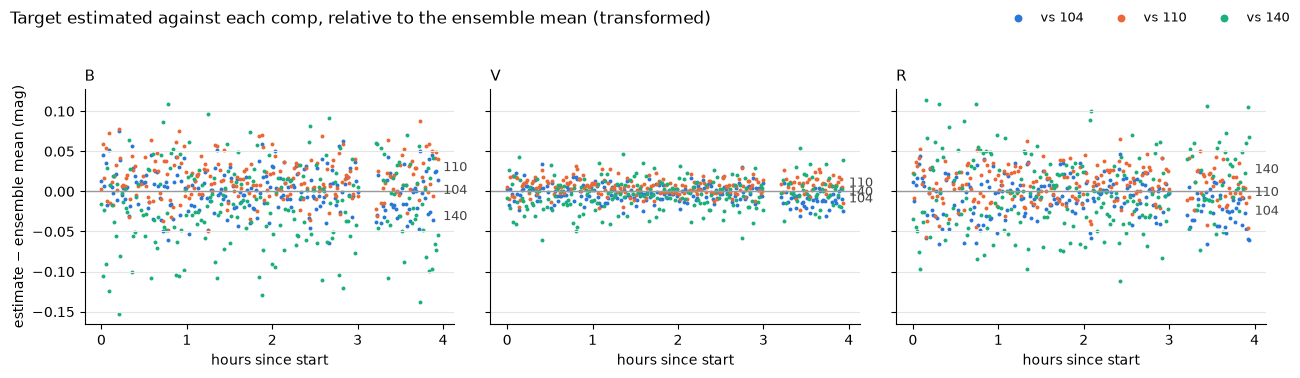

In [22]:
SERIES = {"104": "#2a78d6", "110": "#eb6834", "140": "#1baf7a"}   # fixed categorical order
dev = per_comp.sub(per_comp.mean(axis=1), axis=0).assign(FILT=ens["FILT"], JD=ens["DATE"])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, f in zip(axes, "BVR"):
    sub = dev[dev["FILT"] == f]
    hours = (sub["JD"] - sub["JD"].min()) * 24
    for c, color in SERIES.items():
        ax.scatter(hours, sub[c], s=8, color=color, label=f"vs {c}", linewidths=0)
        ax.annotate(c, (hours.iloc[-1], sub[c].iloc[-20:].median()), xytext=(4, 0),
                    textcoords="offset points", va="center", fontsize=9, color="#444")
    ax.axhline(0, color="#999", linewidth=1)
    ax.set_title(f, loc="left", fontsize=11)
    ax.set_xlabel("hours since start")
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("estimate − ensemble mean (mag)")
fig.suptitle("Target estimated against each comp, relative to the ensemble mean (transformed)", x=0.01, ha="left")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=3, frameon=False, fontsize=9, markerscale=2)
fig.tight_layout(rect=(0, 0, 1, 0.95))

Two different things can make comps disagree, and the chart separates them:

- **A steady offset** (a dot cloud sitting above or below zero all night) means a catalog
  error, or a color the transform didn't fully fix. With the fixed 8 px aperture and the
  transform, none of the three comps has much of one, including 110, the blend.
- **Frame-to-frame scatter** is measurement noise. 140 (green) scatters far more than the
  others: it's 14.7 in B, about 3.5 mag fainter than CY Aqr, so its own photon noise is
  large. That's why comps are supposed to be close in brightness to the target.

In [23]:
offsets = dev.groupby("FILT")[list(SERIES)].median().loc[["B", "V", "R"]]
scatter = pd.DataFrame({c: (per_comp[c] - per_comp["104"]).groupby(ens["FILT"]).std() for c in ["110", "140"]}).loc[["B", "V", "R"]]
pd.concat({"steady offset (median)": offsets, "scatter vs 104 (std)": scatter}, axis=1)

steady offset (median)                scatter vs 104 (std)       
                        104    110     140                  110    140
FILT                                                                  
B                    0.0017 0.0118 -0.0150               0.0143 0.0743
V                   -0.0034 0.0065 -0.0029               0.0078 0.0295
R                   -0.0058 0.0084 -0.0015               0.0129 0.0679

The per-frame spread across comps, which becomes MERR, is the scatter between the three
dots at any moment:

In [24]:
spread = engine.comp_estimates(ens_report, general, COMPS, catalog, coeffs)
summary = pd.DataFrame({
    "median comp spread": spread.groupby(ens["FILT"])["std"].median(),
    "median SNR MERR": method_a.groupby("FILT")["MERR"].median(),
}).loc[["B", "V", "R"]]
summary["median ensemble MERR"] = np.hypot(summary["median comp spread"], summary["median SNR MERR"])
summary["spread without 140"] = per_comp[["104", "110"]].std(axis=1).groupby(ens["FILT"]).median()
summary["with naive reading (old)"] = [0.063, 0.017, 0.040]
summary

,median comp spread,median SNR MERR,median ensemble MERR,spread without 140,with naive reading (old)
FILT,,,,,
B,0.0317,0.0030,0.0319,0.0103,0.0630
V,0.0121,0.0030,0.0124,0.0055,0.0170
R,0.0282,0.0060,0.0288,0.0120,0.0400


The comp spread dominates the SNR error everywhere, so for an ensemble light curve the
MERR is really a statement about how well the comps agree. Here that's mostly 140's noise:
dropping it would cut the B and R spread by more than half. (With only two comps left,
though, the spread itself becomes a shaky estimate, so a better fix is a brighter third
comp.)

## 8. Summary

- **Single comp:** Δ = target − comp in each filter. The transform adds a color correction,
  coefficient × (target − comp color). Everything needed is in the AAVSO report row.
- **Ensemble:** VPhot's ensemble is an unweighted average comp, and the report carries
  its average catalog and instrumental magnitudes. The transform is linear, so
  transforming against that average comp equals transforming against each comp and
  averaging (the "multiple single-comp TA runs" workflow). That's the app's method.
- **The catch** is uncertainty. The comp-to-comp spread needs per-comp data from the
  General Report, where VPhot measures each comp against the *other* comps.
- **Not exact for:** weighted ensembles (e.g. SNR-weighted) or comps missing from some
  filters.